Training
0 2.3582 9.180000000000001
50 0.601 83.5
100 0.3859 89.12
150 0.3025 91.32000000000001
200 0.2649 92.39
250 0.2376 93.22
300 0.2213 93.66
350 0.203 94.17
400 0.1894 94.56
450 0.1781 94.92


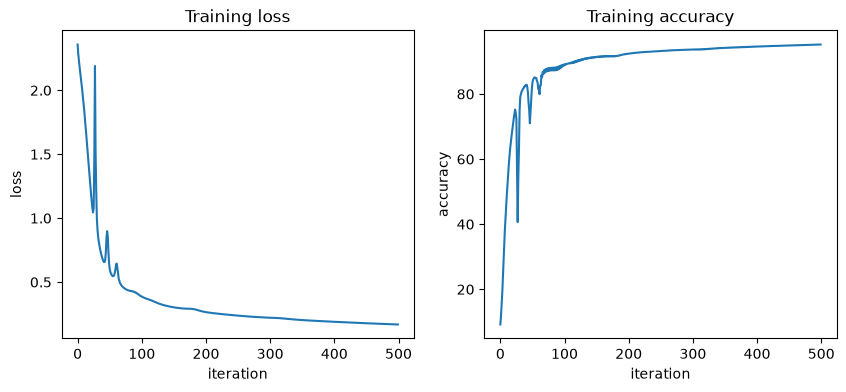

Testing
Test accuracy: 94.89


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Training")
data=np.array(pd.read_csv("/Users/yuktaranjalkar/Downloads/mnist_train.csv"))

y=data[:,0]
x=data[:, 1:]/255.0

sizes=[784,128,64,32,10]

def param():
    W=[]
    B=[]
    for i in range(len(sizes)-1):
        W.append(np.random.randn(sizes[i], sizes[i+1])*np.sqrt(2/sizes[i]))
        B.append(np.zeros((1,sizes[i+1])))
    return W, B

def relu(z):
    return np.maximum(0, z)

def softmax(z):
    expZ=np.exp(z-np.max(z, axis=1, keepdims=True))
    return expZ/np.sum(expZ, axis=1, keepdims=True)

def onehot(y):
    Y=np.zeros((y.size,10))
    Y[np.arange(y.size),y]=1
    return Y

def cross_entropy(a2,Y):
    m=Y.shape[0]
    return -np.sum(Y*np.log(a2+1e-9))/m

def forward(x,W,B):
    Z=[]
    A=[x]
    for i in range(len(W)-1):
        z=A[-1]@W[i]+B[i]
        Z.append(z)
        A.append(relu(z))
    z=A[-1]@W[-1]+B[-1]
    Z.append(z)
    A.append(softmax(z))
    return Z,A


def backward(Y,Z,A,W):
    m=Y.shape[0]
    L=len(W)
    dW=[None]*L
    dB=[None]*L
    dz=A[-1]-Y
    for i in reversed(range(L)):
        dW[i]=A[i].T@dz/m
        dB[i]=np.sum(dz,axis=0,keepdims=True)/m
        if i>0:
            dz=(dz@W[i].T)*(Z[i-1]>0)
    return dW, dB

def update(W,B,dW,dB):
    for i in range(len(W)):
        W[i]=W[i]-0.1*dW[i]
        B[i]=B[i]-0.1*dB[i]
    return W, B

Y=onehot(y)
W,B=param()

losses=[]
accs=[]

for i in range(500):
    Z,A=forward(x,W,B)
    loss=cross_entropy(A[-1], Y)
    acc=np.mean(np.argmax(A[-1], axis=1)==y)
    losses.append(loss)
    accs.append(acc*100)

    dW, dB=backward(Y,Z,A,W)
    W,B=update(W,B,dW,dB)

    if i%50==0:
        print(i, round(loss,4), round(acc,4)*100)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("loss")
plt.title("Training loss")

plt.subplot(1,2,2)
plt.plot(accs)
plt.xlabel("iteration")
plt.ylabel("accuracy")
plt.title("Training accuracy")

plt.show()

print("Testing")

testdata=np.array(pd.read_csv("/Users/yuktaranjalkar/Downloads/mnist_test.csv"))

yt=testdata[:,0]
xt=testdata[:,1:]/255.0

Zt,At=forward(xt,W,B)


test_acc = np.mean(np.argmax(At[-1], axis=1) == yt)
print("Test accuracy:", round(test_acc, 4)*100)
